> **AI for RO · phase 1: can AI see fouling coming?** — part of Project 3 of [chemai](https://github.com/EngMtaleb/chemai/tree/main/projects/p03_ai_for_ro). This notebook was written as “phase 3”: its code, its printed lines and the declaration appended at the end keep the names they were written with. Working names → the episode: phase 3 → **phase 1**, phase 3b → **phase 1B**, phase 4 → **phase 3**, phase 1 → **the lab study**; phase 2 keeps its number.

# Fouling forecast, re-tested — phase 1

**Questions**
1. Can any method forecast a train's fouling indicators 1, 3, 7 and 14 days ahead better than assuming *no change*?
2. Does a 90 % range around the forecast hold on days the model never saw?
3. Can a forecast see the normalised feed-channel ΔP crossing +15 % before it happens?
4. How much of any gain comes from reading *today's* state better, rather than from predicting the change?

**Data:** one seawater RO plant — 3 trains, day 0–771, 18 cleanings (CIP). Daily indicators, each a fractional rise from a
baseline: `dp_pct` (normalised feed-channel ΔP), `flux_pct` (loss of 25 °C specific flux, floored at 0), `sp_pct` (25 °C salt
passage) and `ndp_pct` (net driving pressure). The deposit's dictionary puts all four on the fixed commissioning baseline; the
data agree for `dp_pct`, but `ndp_pct` falls back to zero after each cleaning — it is reset (the earlier RO-fouling project of this repository found this). Paper: Su, Meng & Chang (2026),
*Auditable Clean-in-Place Decision Support from Routine SWRO SCADA: Selecting Differential-Pressure Recovery and Falsifying
a Per-CIP-Reset Trigger*, *Membranes* 16(8) 257, doi:10.3390/membranes16080257.
Data: Su (2026), Zenodo — version 3 (30 June 2026) of the deposit the paper cites (all versions: doi:10.5281/zenodo.21003996;
this version: doi:10.5281/zenodo.21055948), CC BY 4.0. No raw 10-min data, no feed quality, no temperature: every method
learns only from the indicators' own history, the cleaning days and the daily count of 10-min samples.

**The earlier test** (7 days ahead, same data; notebook `fouling_prediction_two_ways.ipynb`): on future data no method beat
*no change*. This re-test was declared in full
before any of its models was run — horizons, methods, settings, splits, scores, the success rule, the ranges and the
early-warning rule. The earlier test did shape it (the LSTM was dropped). The declaration, with the corrections made after
the run, is reproduced at the end of the notebook.

Run all: about 8 minutes in our run, on a 2-core machine.

In [1]:
import hashlib, io, urllib.request, zipfile, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import r2_score
pd.set_option("display.width", 200)
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#d03b3b"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "figure.facecolor": SURF, "axes.facecolor": SURF})
def style(ax):
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
import sklearn, xgboost
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "\n(the numbers in the text came from numpy 2.5.3, pandas 3.0.5, scikit-learn 1.9.1, xgboost 3.4.1; other versions can move the last digits)")

numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1 
(the numbers in the text came from numpy 2.5.3, pandas 3.0.5, scikit-learn 1.9.1, xgboost 3.4.1; other versions can move the last digits)


## 1 · Download the deposit and check it

The zip is checked against the MD5 printed on the Zenodo record, and the two data files against the deposit's own SHA-256 list.

In [2]:
URL = "https://zenodo.org/records/21055948/files/ESWRT_reproducibility_deposit_v1.3-20260630.zip?download=1"
MD5 = "68b0223978f0e674d51cfc4c24e95435"
SHA = {"derived_daily_indicator_table.csv": "50ad81cb632dfc74e710bad70ce9bf08a014061d0ef7b602be25fc465f1f6374",
       "cip_campaign_ledger.csv": "4f65351d8aaa96d8c804c63d3257978dd22628553e7ab4e12d08f1aa0a375ca7"}
DATA = Path("data")
if not all((DATA / n).exists() for n in SHA):
    raw = urllib.request.urlopen(urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"}), timeout=180).read()
    assert hashlib.md5(raw).hexdigest() == MD5, "not the published zip"
    z = zipfile.ZipFile(io.BytesIO(raw)); DATA.mkdir(exist_ok=True)
    for n in SHA:
        (DATA / n).write_bytes(z.read("data/" + n))
for n, sha in SHA.items():
    assert hashlib.sha256((DATA / n).read_bytes()).hexdigest() == sha, f"{n}: not the published file"
d = pd.read_csv(DATA / "derived_daily_indicator_table.csv").sort_values(["train", "day_index"]).reset_index(drop=True)
led = pd.read_csv(DATA / "cip_campaign_ledger.csv")
print(f"{len(d)} train-days, {len(led)} cleanings; the files match the published deposit")

1340 train-days, 18 cleanings; the files match the published deposit


## 2 · The tables, the methods and the scores (declared)

- **Pairs:** (train, day *t*) → the same train on day *t + h*, h = 1, 3, 7, 14. Both days must have data and no cleaning may fall in
  (t, t + h]: we forecast fouling, not the decision to clean.
- **Inputs** (known on day *t*): today's four indicators; their values 1, 3, 7 and 14 days back (nearest earlier day within 2 days);
  the 14-day slope of ΔP and flux inside the current cycle; days since the last cleaning; the number of 10-min samples behind
  today's value; the smoothed state; the fouling-law forecast. No train label.
- **Methods:** (1) **no change**; (2) **smoothed no change** — the median of the last three observations of the cycle within 7 days;
  (3) **trend** — the 14-day slope extrapolated; (4) **fouling law** — a straight line through the current cleaning cycle,
  extrapolated; (5) **XGBoost** on the change (400 trees, learning rate 0.03, depth 4, subsample 0.8, column sample 0.8,
  min child weight 5, the average of 5 seeds); (6) **hybrid** — the fouling law plus XGBoost trained on its error.
- **Scores:** MAE in percentage points; **skill** = 1 − MAE / MAE(no change); R² of the *change* (a level R² looks good for any
  method that copies today's value). A method **beats no change** only if its skill over the whole test is at least +5 % and
  positive in at least 3 of the 4 test blocks.

*Details:* the smoothed state falls back to today's value when the cycle has no earlier observation (the day of a cleaning);
days since the last cleaning are empty before a train's first cleaning; the rule "(t, t + h]" keeps pairs whose day *t* is
itself a cleaning day — that day's value can still show the state before the cleaning — and sections 5 and 6 show the
results without them.

In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

IND = ["dp_pct", "flux_pct", "sp_pct", "ndp_pct"]
TARGETS = ["dp_pct", "flux_pct"]
HORIZONS = (1, 3, 7, 14)
BLOCKS = [(550, 600), (600, 650), (650, 700), (700, 772)]
METHODS = ["no change", "smoothed no change", "trend", "fouling law", "XGBoost", "hybrid"]
SEEDS = (0, 1, 2, 3, 4)
XGB = dict(n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
           n_jobs=2, verbosity=0)


# ------------------------------------------------------------------ tables
def near(s, day, tol=2):
    for k in range(tol + 1):
        if day - k in s.index:
            return s[day - k]
    return np.nan


def law_forecast(cyc, c, t, h, min_pts=5):
    """fouling law: linear growth since the last cleaning, fitted on the cycle so far, extrapolated to t + h."""
    if len(cyc) < min_pts:
        return np.nan
    b, a = np.polyfit(cyc.index.values.astype(float), cyc[c].values, 1)
    return float(np.clip(a + b * (t + h), 0, 1))


def build_days(d, led):
    """one row per (train, day t, horizon h) with the inputs known on day t; y and `valid` where a pair exists."""
    rows = []
    for tr, g in d.groupby("train"):
        g = g.set_index("day_index").sort_index()
        cips = np.sort(led[led.train == tr].day_index.values)
        for t in g.index:
            last = cips[cips <= t].max() if (cips <= t).any() else -1
            cyc = g[(g.index > last) & (g.index <= t)]
            base = {"train": tr, "t": int(t), "days_since_cip": float(t - last) if last >= 0 else np.nan,
                    "n_samples": float(g.at[t, "n_10min_samples"])}
            for c in IND:
                base[c] = float(g.at[t, c])
                for lag in (1, 3, 7, 14):
                    base[f"{c}_lag{lag}"] = near(g[c], t - lag)
            recent = cyc[cyc.index > t - 14]
            recent3 = cyc[cyc.index > t - 7].tail(3)
            for c in TARGETS:
                base[f"{c}_slope14"] = float(np.polyfit(recent.index, recent[c], 1)[0]) if len(recent) >= 4 else np.nan
                base[f"{c}_state"] = float(recent3[c].median()) if len(recent3) else float(g.at[t, c])
            for h in HORIZONS:
                valid = (t + h in g.index) and not ((cips > t) & (cips <= t + h)).any()
                r = dict(base, h=h, valid=valid)
                for c in TARGETS:
                    r[f"y_{c}"] = float(g.at[t + h, c]) if valid else np.nan
                    r[f"{c}_law"] = law_forecast(cyc, c, t, h)
                rows.append(r)
    df = pd.DataFrame(rows)
    df["block"] = -1
    for i, (a, b) in enumerate(BLOCKS):
        df.loc[(df.t >= a) & (df.t < b), "block"] = i
    return df


def features(df):
    return [c for c in df.columns if c not in ("train", "t", "h", "valid", "block") and not c.startswith("y_")]


# ------------------------------------------------------------------ methods
def simple(df, c, h):
    """the four methods that need no training: arrays aligned with df."""
    now = df[c].to_numpy()
    trend = np.clip(now + h * np.nan_to_num(df[f"{c}_slope14"].to_numpy()), 0, 1)
    law = df[f"{c}_law"].to_numpy()
    return {"no change": now, "smoothed no change": df[f"{c}_state"].to_numpy(),
            "trend": trend, "fouling law": np.where(np.isnan(law), now, law)}


def fit_xgb(X, y, seeds=SEEDS):
    from xgboost import XGBRegressor
    return [XGBRegressor(random_state=s, **XGB).fit(X, y) for s in seeds]


def predict_xgb(models, X):
    return np.mean([m.predict(X) for m in models], axis=0)


def learned(train, tests, c, h, feats):
    """XGBoost (on the change) and hybrid (on the fouling law's error): fit on `train`, predict every frame in `tests`."""
    X = train[feats].to_numpy(float)
    now = train[c].to_numpy(); y = train[f"y_{c}"].to_numpy()
    law = simple(train, c, h)["fouling law"]
    m_x, m_h = fit_xgb(X, y - now), fit_xgb(X, y - law)
    out = []
    for te in tests:
        Xt = te[feats].to_numpy(float); s = simple(te, c, h)
        out.append({"XGBoost": np.clip(s["no change"] + predict_xgb(m_x, Xt), 0, 1),
                    "hybrid": np.clip(s["fouling law"] + predict_xgb(m_h, Xt), 0, 1)})
    return out


def forecasts(train, tests, c, h, feats):
    """all six methods for each test frame."""
    lr = learned(train, tests, c, h, feats)
    return [{**simple(te, c, h), **l} for te, l in zip(tests, lr)]


# ------------------------------------------------------------------ scores
def scores(y, now, preds):
    base = np.mean(np.abs(y - preds["no change"]))
    out = {}
    for m, p in preds.items():
        mae = np.mean(np.abs(y - p))
        out[m] = {"MAE_pp": 100 * mae, "skill_pct": 100 * (1 - mae / base), "R2_change": r2_score(y - now, p - now)}
    return out


def verdict(pooled_skill, block_skills):
    return bool(pooled_skill >= 5.0 and sum(s > 0 for s in block_skills) >= 3)

In [4]:
t0 = time.time()
days = build_days(d, led)
pairs = days[days.valid].reset_index(drop=True)
feats = features(days)
cnt = pairs.assign(part=np.where(pairs.block < 0, "before day 550 (training only)", "test blocks, days 550-771"))
display(cnt.groupby(["part", "h"]).size().unstack())
print(f"{len(feats)} inputs; built in {time.time() - t0:.0f} s")

h,1,3,7,14
part,,,,
before day 550 (training only),527,466,422,379
"test blocks, days 550-771",642,617,572,502


28 inputs; built in 4 s


## 3 · Look first: ΔP, cleanings and the events to see coming

**Event (onset):** the first day a train's 7-day median ΔP rise (at least 3 values in the 7 days) reaches +15 % after at least
14 days below it (every 7-day median in those 14 days below; at least one must exist). +15 % is the membrane maker's cleaning
criterion: "Normalized pressure drop from feed to concentrate has increased 15%" (LG Chem's cleaning criteria, as quoted in
the deposit's `analysis_outputs/lg_official_criteria_opchar.json`). Grey: the test period. Before day 300 the record is sparse
(50–53 days per train): start-up values up to 100 % on days 9–18, off this scale, and a one-day spike on day 51. The "onsets"
the start-up makes (trains A and C, day 11) are not fouling events, are not marked and enter no score.

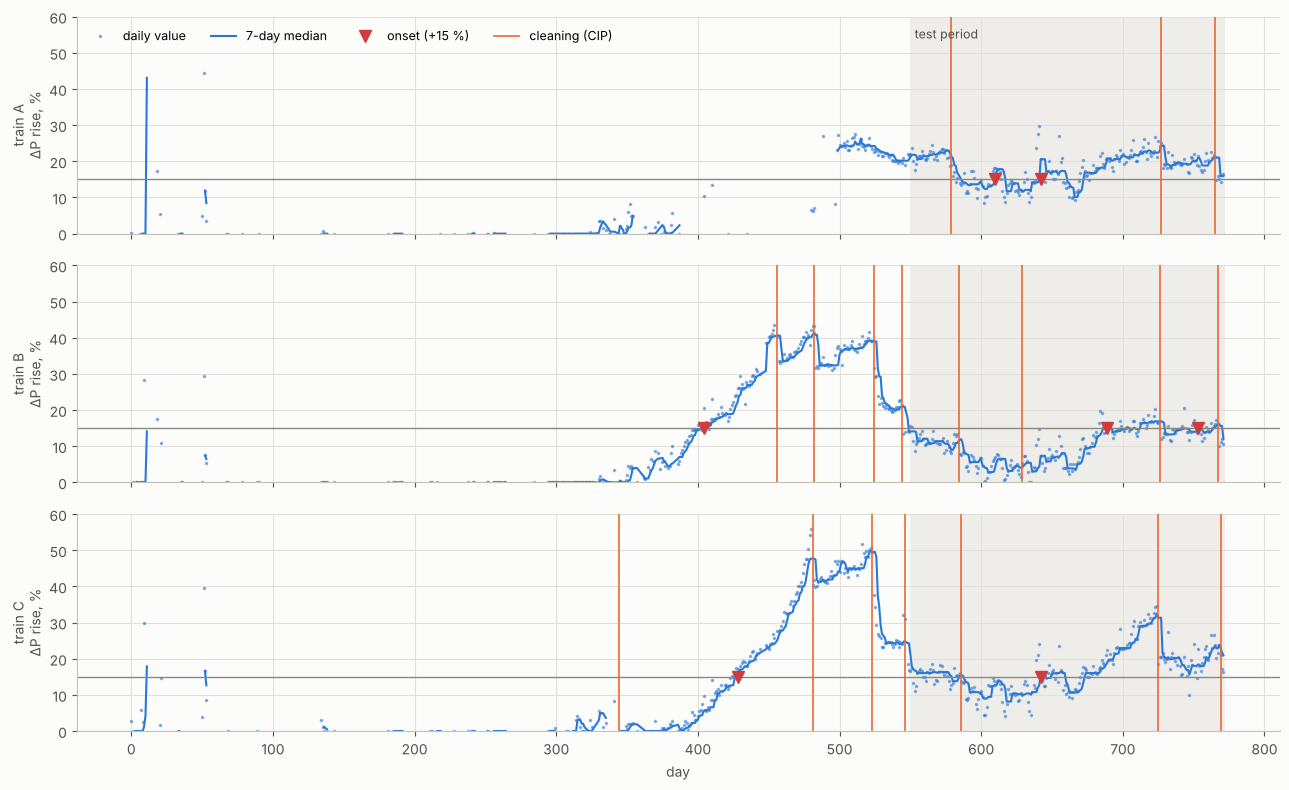

onsets in the test period: {'15 %': [['A', 610], ['A', 642], ['B', 689], ['B', 753], ['C', 642]], '20 %': [['A', 642], ['A', 689], ['A', 750], ['C', 694], ['C', 759]]}
highest 7-day median, days 300-549: {'A': 26.3, 'B': 41.5, 'C': 49.9}
7-day median in the test period, min and max: {'A': (10.2, 24.3), 'B': (2.9, 16.9), 'C': (8.2, 32.5)}
before day 300 - days with data: {'A': 50, 'B': 52, 'C': 53} | highest daily ΔP rise on days 9-18: {'A': 100.0, 'B': 100.0, 'C': 100.0} | on day 51: {'A': 44.3, 'B': 29.4, 'C': 39.6}
onsets before day 300 (not marked): {'15 %': [['A', 11], ['C', 11]], '20 %': [['A', 11]]}
flux loss: lowest value 0.0 %; in the test period exactly 0 on 59 % of train-days, median 0.0 %


In [5]:
def median7(d):
    out = []
    for tr, g in d.groupby("train"):
        g = g.set_index("day_index").sort_index()
        for t in g.index:
            w = g.dp_pct[(g.index > t - 7) & (g.index <= t)]
            if len(w) >= 3:
                out.append({"train": tr, "day": int(t), "m7": float(w.median())})
    return pd.DataFrame(out)

def onsets(m7, thr):
    out = []
    for tr, s in m7.groupby("train"):
        s = s.set_index("day").m7
        for t, v in s.items():
            if v < thr:
                continue
            before = s[(s.index >= t - 14) & (s.index < t)]
            if len(before) and (before < thr).all():
                out.append({"train": tr, "day": int(t)})
    return pd.DataFrame(out)

M7 = median7(d)
EV = {thr: onsets(M7, thr) for thr in (0.15, 0.20)}
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for ax, tr in zip(axes, "ABC"):
    style(ax); g = d[d.train == tr]; m = M7[M7.train == tr].set_index("day").m7
    gap = m.index.to_series().diff() > 7
    m = pd.concat([m, pd.Series(np.nan, index=m.index[gap] - 0.5)]).sort_index()
    ax.axvspan(550, 772, color=GRID, alpha=0.5, lw=0)
    ax.plot(g.day_index, 100 * g.dp_pct, ".", color=BLUE, ms=3, alpha=0.5, label="daily value")
    ax.plot(m.index, 100 * m.values, "-", color=BLUE, lw=1.5, label="7-day median")
    ax.axhline(15, color=MUTED, lw=1)
    for c in led[led.train == tr].day_index:
        ax.axvline(c, color=ORANGE, lw=1.2)
    e = EV[0.15][(EV[0.15].train == tr) & (EV[0.15].day >= 300)]
    ax.plot(e.day, [15] * len(e), "v", color=RED, ms=9, label="onset (+15 %)")
    ax.set_ylabel(f"train {tr}\nΔP rise, %"); ax.set_ylim(0, 60)
axes[0].plot([], [], color=ORANGE, lw=1.2, label="cleaning (CIP)"); axes[0].legend(frameon=False, fontsize=9, loc="upper left", ncol=4)
axes[0].text(553, 54, "test period", color=INK2, fontsize=9); axes[-1].set_xlabel("day")
plt.tight_layout(); plt.show()
print("onsets in the test period:", {f"{int(100 * k)} %": v[v.day >= 550][["train", "day"]].values.tolist() for k, v in EV.items()})
pk = M7[(M7.day < 550) & (M7.day >= 300)].groupby("train").m7.max()
rg = M7[M7.day >= 550].groupby("train").m7.agg(["min", "max"])
print("highest 7-day median, days 300-549:", (100 * pk).round(1).to_dict())
print("7-day median in the test period, min and max:", {k: (round(100 * float(r["min"]), 1), round(100 * float(r["max"]), 1)) for k, r in rg.iterrows()})
early = d[d.day_index < 300]
print("before day 300 - days with data:", early.groupby("train").size().to_dict(),
      "| highest daily ΔP rise on days 9-18:", (100 * early[early.day_index.between(9, 18)].groupby("train").dp_pct.max()).round(1).to_dict(),
      "| on day 51:", (100 * early[early.day_index == 51].set_index("train").dp_pct).round(1).to_dict())
print("onsets before day 300 (not marked):", {f"{int(100 * k)} %": v[v.day < 300][["train", "day"]].values.tolist() for k, v in EV.items()})
te = d[d.day_index >= 550]
print(f"flux loss: lowest value {100 * d.flux_pct.min():.1f} %; in the test period exactly 0 on {100 * (te.flux_pct == 0).mean():.0f} % "
      f"of train-days, median {100 * te.flux_pct.median():.1f} %")

## 4 · Run both tests

1. **The future, rolling origin:** four test blocks by day *t* — 550–599, 600–649, 650–699, 700–771. Each block's models train on
   every pair whose target day falls before the block starts (all trains, all earlier days).
2. **An unseen train, in the future:** the same blocks, but the models train on the other two trains only.

The same loop makes each method's **90 % range**: the last quarter of the block's training pairs (by day, starting at a whole day)
is set aside; the method is refitted on the pairs whose target day is before that quarter starts, and its errors on the quarter —
days it did not see — give the 90th percentile. (The first run had no gap here; see the corrections.) The loop also makes the
**daily ΔP forecasts** that the early warning reads. About eight minutes.

In [6]:
t0 = time.time()
ro, lo, wd = [], [], []
for c in TARGETS:
    for h in HORIZONS:
        P, D = pairs[pairs.h == h], days[days.h == h]
        for b, (start, _) in enumerate(BLOCKS):
            train = P[P.t + h < start].sort_values(["t", "train"])
            test, alld = P[P.block == b], D[D.block == b]
            f_test, f_days = forecasts(train, [test, alld], c, h, feats)
            cal_start = train.t.iloc[int(round(0.75 * len(train)))]
            calib, fit = train[train.t >= cal_start], train[train.t + h < cal_start]
            (f_cal,) = forecasts(fit, [calib], c, h, feats)
            q = {m: float(np.quantile(np.abs(calib[f"y_{c}"].to_numpy() - f_cal[m]), 0.9)) for m in METHODS}
            base = test[["train", "t", c, f"y_{c}"]].rename(columns={c: "now", f"y_{c}": "y"})
            ro.append(base.assign(target=c, h=h, block=b, **{m: f_test[m] for m in METHODS}, **{f"q90 {m}": q[m] for m in METHODS}))
            if c == "dp_pct" and h in (7, 14):
                wd.append(alld[["train", "t", c]].rename(columns={c: "now"}).assign(h=h, block=b, **{m: f_days[m] for m in METHODS}))
            for k_out in "ABC":
                tr_k, te_k = train[train.train != k_out], test[test.train == k_out]
                if te_k.empty:
                    continue
                (f_k,) = forecasts(tr_k, [te_k], c, h, feats)
                base = te_k[["train", "t", c, f"y_{c}"]].rename(columns={c: "now", f"y_{c}": "y"})
                lo.append(base.assign(target=c, h=h, block=b, **{m: f_k[m] for m in METHODS}))
    print(f"{c} done [{time.time() - t0:.0f} s]")
RO, LO, WD = (pd.concat(x, ignore_index=True) for x in (ro, lo, wd))

dp_pct done [217 s]


flux_pct done [468 s]


## 5 · Results: the future, rolling origin

In [7]:
def forecast_scores(p):
    rows = []
    for (c, h), g in p.groupby(["target", "h"]):
        pooled = scores(g.y.to_numpy(), g.now.to_numpy(), {m: g[m].to_numpy() for m in METHODS})
        blocks = {b: scores(gb.y.to_numpy(), gb.now.to_numpy(), {m: gb[m].to_numpy() for m in METHODS}) for b, gb in g.groupby("block")}
        for m in METHODS:
            bs = [blocks[b][m]["skill_pct"] for b in sorted(blocks)]
            rows.append({"target": c, "h": h, "method": m, "n": len(g), **pooled[m],
                         **{f"skill block {b + 1}": s for b, s in enumerate(bs)},
                         "beats no change": verdict(pooled[m]["skill_pct"], bs) if m != "no change" else None})
    return pd.DataFrame(rows)

def show(fs, title):
    for c in TARGETS:
        f = fs[fs.target == c]
        base = f[f.method == "no change"].set_index("h").MAE_pp
        print(f"{title} · {c} · no change MAE (percentage points): " + ", ".join(f"{h} d: {v:.2f}" for h, v in base.items()))
        t = f.pivot(index="method", columns="h", values="skill_pct").loc[METHODS].round(1)
        t.columns = [f"skill % at {h} d" for h in t.columns]
        win = f[f["beats no change"] == True]
        display(t)
        print("beats no change by the declared rule:", win[["h", "method"]].values.tolist() or "none")

FS_RO = forecast_scores(RO)
show(FS_RO, "rolling origin")

rolling origin · dp_pct · no change MAE (percentage points): 1 d: 1.76, 3 d: 2.83, 7 d: 2.91, 14 d: 3.49


,skill % at 1 d,skill % at 3 d,skill % at 7 d,skill % at 14 d
method,,,,
no change,0.0,0.0,0.0,0.0
smoothed no change,-20.8,2.2,1.8,3.6
trend,-4.5,-12.5,-26.4,-53.2
fouling law,-48.5,-6.3,-16.2,-20.4
XGBoost,-15.7,-0.8,-9.3,-14.6
hybrid,-50.4,-36.6,-24.9,-32.2


beats no change by the declared rule: none
rolling origin · flux_pct · no change MAE (percentage points): 1 d: 2.11, 3 d: 3.07, 7 d: 3.48, 14 d: 4.31


,skill % at 1 d,skill % at 3 d,skill % at 7 d,skill % at 14 d
method,,,,
no change,0.0,0.0,0.0,0.0
smoothed no change,-15.9,1.4,2.7,7.1
trend,-3.1,-8.9,-22.1,-27.3
fouling law,-44.9,-13.6,-7.9,1.0
XGBoost,-12.1,-2.7,-5.8,3.6
hybrid,-28.7,-16.9,-18.7,-3.3


beats no change by the declared rule: [[14, 'smoothed no change']]


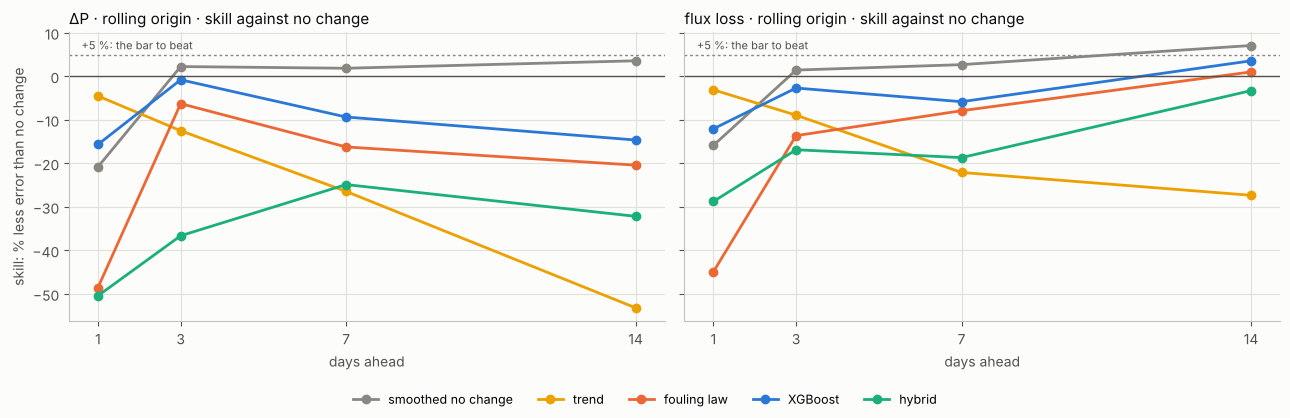

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
cols = {"smoothed no change": MUTED, "trend": YELLOW, "fouling law": ORANGE, "XGBoost": BLUE, "hybrid": AQUA}
for ax, c in zip(axes, TARGETS):
    style(ax); f = FS_RO[FS_RO.target == c]
    for m, col in cols.items():
        g = f[f.method == m].sort_values("h")
        ax.plot(g.h, g.skill_pct, "-o", color=col, lw=2, ms=6, label=m)
    ax.axhline(0, color=INK2, lw=1); ax.axhline(5, color=MUTED, lw=1, ls=(0, (2, 2)))
    ax.text(0.6, 5.6, "+5 %: the bar to beat", color=INK2, fontsize=8, va="bottom")
    ax.set_xticks(HORIZONS); ax.set_xlabel("days ahead"); ax.set_xlim(0.3, 14.7)
    ax.set_title(("ΔP" if c == "dp_pct" else "flux loss") + " · rolling origin · skill against no change", loc="left", color=INK, fontsize=11)
axes[0].set_ylabel("skill: % less error than no change")
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=9, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

**A look at the forecasts** — train C, ΔP, 7 days ahead, rolling origin (an illustration; no new score).

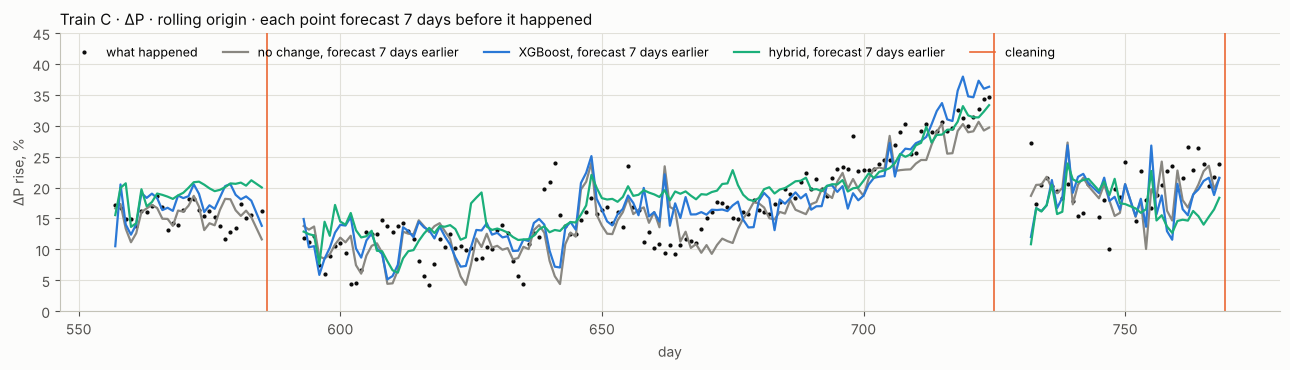

In [9]:
g = RO[(RO.target == "dp_pct") & (RO.h == 7) & (RO.train == "C")].sort_values("t").set_index("t")
gaps = g.index.to_series().diff() > 2
g = pd.concat([g, pd.DataFrame(np.nan, index=g.index[gaps] - 0.5, columns=g.columns)]).sort_index()   # no line across a gap
fig, ax = plt.subplots(figsize=(13, 3.8)); style(ax)
ax.plot(g.index + 7, 100 * g.y, ".", color=INK, ms=4, label="what happened")
for m, col in (("no change", MUTED), ("XGBoost", BLUE), ("hybrid", AQUA)):
    ax.plot(g.index + 7, 100 * g[m].astype(float), "-", color=col, lw=1.6, label=f"{m}, forecast 7 days earlier")
for cd in led[(led.train == "C") & (led.day_index >= 550)].day_index:
    ax.axvline(cd, color=ORANGE, lw=1.2)
ax.plot([], [], color=ORANGE, lw=1.2, label="cleaning"); ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=5)
ax.set_xlabel("day"); ax.set_ylabel("ΔP rise, %"); ax.set_ylim(0, 45)
ax.set_title("Train C · ΔP · rolling origin · each point forecast 7 days before it happened", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()

In [10]:
def r2_table(fs):
    t = fs.pivot_table(index=["target", "method"], columns="h", values="R2_change")
    t = t.reindex(pd.MultiIndex.from_product([TARGETS, METHODS])).round(2)
    t.columns = [f"R² of the change, {h} d" for h in t.columns]
    return t

def block_table(fs):
    b = fs.set_index(["target", "h", "method"])[[f"skill block {i + 1}" for i in range(4)]].round(1)
    return b[b.index.get_level_values("method") != "no change"]

display(r2_table(FS_RO)); display(block_table(FS_RO))

R² of the change, 1 d  R² of the change, 3 d  R² of the change, 7 d  R² of the change, 14 d
dp_pct   no change                           -0.00                  -0.00                  -0.02                   -0.07
         smoothed no change                  -0.35                   0.04                   0.07                    0.02
         trend                               -0.09                  -0.26                  -0.61                   -1.52
         fouling law                         -1.01                  -0.10                  -0.17                   -0.43
         XGBoost                             -0.44                  -0.01                  -0.12                   -0.43
         hybrid                              -1.06                  -0.90                  -0.32                   -1.12
flux_pct no change                           -0.00                  -0.00                  -0.00                   -0.00
         smoothed no change                  -0.20                   0.05                   0.04                    0.11
         trend                               -0.05                  -0.16                  -0.40                   -0.73
         fouling law                         -0.32                   0.00                   0.06                    0.09
         XGBoost                              0.08                   0.13                   0.15                    0.13
         hybrid                              -0.11                  -0.09                  -0.10                   -0.01

skill block 1  skill block 2  skill block 3  skill block 4
target   h  method                                                                        
dp_pct   1  smoothed no change          -27.7          -52.0          -14.1            1.7
            trend                        -6.6           -5.2           -7.1           -1.1
            fouling law                 -68.1          -50.0          -62.2          -27.3
            XGBoost                     -20.6           -6.8          -53.0            5.8
            hybrid                      -76.2          -68.9          -73.5           -6.7
         3  smoothed no change            8.7           -5.6            0.9            8.9
            trend                       -14.2          -12.3          -19.3           -4.4
            fouling law                 -13.3           12.5          -15.9          -17.1
            XGBoost                      -3.8            6.4           -8.5           -0.6
            hybrid                      -27.7            4.7          -42.0          -99.2
         7  smoothed no change           -3.8            5.0           -2.8            6.0
            trend                       -45.2          -29.6          -31.7           -4.7
            fouling law                 -76.5            9.7          -10.9          -25.9
            XGBoost                     -42.6            2.2            1.4          -19.9
            hybrid                     -111.6            4.5          -24.2          -18.8
         14 smoothed no change            9.9            1.5            2.4            4.0
            trend                       -72.5          -79.3          -42.1          -18.3
            fouling law                 -91.8           -6.7            5.8          -34.2
            XGBoost                     -77.0           -7.9            9.4          -20.7
            hybrid                      -93.2          -32.8           -7.7          -28.6
flux_pct 1  smoothed no change          -24.9          -42.8           -8.0           -8.7
            trend                        -3.8           -4.5           -2.6           -2.8
            fouling law                 -34.6          -79.0          -45.0          -29.7
            XGBoost                     -72.2          -20.1          -15.0            4.9
            hybrid                     -110.0          -41.6          -26.0          -11.4
         3  smoothed no change           10.0           -7.4            8.3           -0.1
            trend                        -4.5          -12.0           -9.0           -7.5
            fouling law                   3.3          -15.5          -26.6           -3.6
            XGBoost                     -81.4           13.0           -8.3            5.9
            hybrid                     -100.2            1.4          -37.6            4.5
         7  smoothed no change          -13.3            8.0           -5.3            7.7
            trend                       -27.0          -17.5          -26.8          -21.0
            fouling law                 -28.7            1.9          -35.8           13.4
            XGBoost                    -196.2           19.0          -22.4           11.0
            hybrid                     -237.8           20.0          -60.0           13.6
         14 smoothed no change           -0.1           16.4            3.5            9.3
            trend                       -25.2          -50.8          -17.3          -28.6
            fouling law                  -9.9           -4.4           -2.5           19.2
            XGBoost                     -23.7           27.3           -2.4            6.2
            hybrid                      -25.3           10.4          -13.2           15.7

**Bias** (added after the run, descriptive): the mean of forecast − truth, in percentage points, over all blocks and block by
block. Positive = forecasts too high. For *no change* it is minus the mean change: positive means the indicator fell.

In [11]:
E = 100 * RO[METHODS].sub(RO.y, axis=0)
E[["target", "h", "block"]] = RO[["target", "h", "block"]]
for c in TARGETS:
    e = E[E.target == c]
    bias = pd.concat({"all blocks": e.groupby("h")[METHODS].mean().stack(),
                      **{f"block {b + 1}": e[e.block == b].groupby("h")[METHODS].mean().stack() for b in range(4)}}, axis=1)
    print(c); display(bias.round(2))

dp_pct


all blocks  block 1  block 2  block 3  block 4
h                                                                    
1  no change                -0.04     0.09    -0.03    -0.12    -0.08
   smoothed no change       -0.19     0.16    -0.14    -0.39    -0.33
   trend                    -0.00    -0.05     0.03    -0.04     0.03
   fouling law              -0.99    -1.28    -1.00    -0.80    -0.92
   XGBoost                  -0.13     0.87     0.16    -1.25    -0.22
   hybrid                    1.18     1.95     0.84     1.78     0.43
3  no change                -0.18     0.34    -0.21    -0.39    -0.39
   smoothed no change       -0.35     0.45    -0.33    -0.65    -0.73
   trend                    -0.08    -0.12     0.01    -0.12    -0.08
   fouling law              -1.14    -1.27    -1.24    -0.92    -1.13
   XGBoost                   0.03     0.93    -0.43    -0.07    -0.19
   hybrid                    2.20     2.92     0.94     2.96     2.04
7  no change                -0.57     0.50    -0.95    -0.76    -0.90
   smoothed no change       -0.72     0.61    -1.08    -1.03    -1.19
   trend                    -0.29    -0.53    -0.31    -0.15    -0.23
   fouling law              -1.49    -1.74    -2.06    -1.00    -1.24
   XGBoost                   0.57     1.78     0.05     0.56     0.07
   hybrid                    1.94     3.66     1.36     3.18    -0.14
14 no change                -1.12     0.05    -0.37    -2.44    -1.38
   smoothed no change       -1.28     0.15    -0.50    -2.71    -1.66
   trend                    -0.50    -2.03     1.18    -1.06    -0.35
   fouling law              -1.96    -3.25    -1.56    -2.16    -0.97
   XGBoost                   2.04     3.42     2.14     1.97     0.72
   hybrid                    2.78     3.18     3.64     3.43     0.48

flux_pct


all blocks  block 1  block 2  block 3  block 4
h                                                                    
1  no change                -0.01     0.02    -0.08    -0.16     0.15
   smoothed no change       -0.23    -0.06    -0.23    -0.70     0.01
   trend                     0.09     0.03     0.03     0.14     0.15
   fouling law              -0.51     0.03    -0.06    -2.41     0.19
   XGBoost                  -0.27     0.63    -0.55    -1.83     0.46
   hybrid                   -0.20     0.93    -0.42    -2.62     0.96
3  no change                -0.01     0.16    -0.15    -0.48     0.35
   smoothed no change       -0.25     0.07    -0.29    -1.02     0.16
   trend                     0.30     0.20     0.20     0.43     0.37
   fouling law              -0.52     0.17    -0.08    -2.74     0.45
   XGBoost                  -0.42     1.44    -0.96    -2.14     0.03
   hybrid                   -1.23     1.63    -0.86    -3.87    -1.49
7  no change                -0.10     0.22    -0.80    -1.10     1.27
   smoothed no change       -0.32     0.12    -0.95    -1.64     1.20
   trend                     0.81     0.36     0.08     1.01     1.67
   fouling law              -0.60     0.24    -0.67    -3.37     1.50
   XGBoost                  -0.67     1.54    -1.53    -3.18     0.79
   hybrid                   -0.92     1.74    -1.26    -5.23     1.44
14 no change                -0.21    -0.91     0.70    -2.42     2.30
   smoothed no change       -0.41    -1.00     0.54    -2.96     2.44
   trend                     2.03    -0.49     2.56     1.83     4.06
   fouling law              -0.98    -0.85     0.84    -4.62     1.61
   XGBoost                  -1.31     0.35    -0.59    -5.65     2.10
   hybrid                   -1.59    -0.03     0.05    -6.69     1.81

**Check: without the pairs that start on a cleaning day** (declared rule kept; this only shows whether they matter). The same
check for the unseen train follows its results in section 6.

In [12]:
cip_days = set(zip(led.train, led.day_index))
def without_cip_start(p, fs, title):
    on = np.array([(tr, t) in cip_days for tr, t in zip(p.train, p.t)])
    a, b = (f[f.method != "no change"].set_index(["target", "h", "method"]) for f in (forecast_scores(p[~on]), fs))
    n = p[on & (p.target == "dp_pct")].groupby("h").size()
    print(f"{title}: pairs dropped, per indicator: {n.sum()} (" + ", ".join(f"{h} d: {v}" for h, v in n.items()) + "); "
          f"verdicts changed: {int((a['beats no change'] != b['beats no change']).sum())}; "
          f"largest change of skill: {(a.skill_pct - b.skill_pct).abs().max():.1f} points")

without_cip_start(RO, FS_RO, "rolling origin")

rolling origin: pairs dropped, per indicator: 29 (1 d: 9, 3 d: 8, 7 d: 6, 14 d: 6); verdicts changed: 0; largest change of skill: 2.6 points


## 6 · Results: an unseen train, in the future

The four methods that do not train (no change, smoothed no change, trend, fouling law) give the same rows as in section 5 by
construction; only XGBoost and the hybrid change. The smoothed state's pass for flux is the same result, not a second one.

In [13]:
FS_LO = forecast_scores(LO)
show(FS_LO, "unseen train")
display(r2_table(FS_LO)); display(block_table(FS_LO))
without_cip_start(LO, FS_LO, "unseen train")

unseen train · dp_pct · no change MAE (percentage points): 1 d: 1.76, 3 d: 2.83, 7 d: 2.91, 14 d: 3.49


,skill % at 1 d,skill % at 3 d,skill % at 7 d,skill % at 14 d
method,,,,
no change,0.0,0.0,0.0,0.0
smoothed no change,-20.8,2.2,1.8,3.6
trend,-4.5,-12.5,-26.4,-53.2
fouling law,-48.5,-6.3,-16.2,-20.4
XGBoost,-22.9,-12.4,-28.5,-24.6
hybrid,-78.0,-58.7,-67.3,-57.9


beats no change by the declared rule: none
unseen train · flux_pct · no change MAE (percentage points): 1 d: 2.11, 3 d: 3.07, 7 d: 3.48, 14 d: 4.31


,skill % at 1 d,skill % at 3 d,skill % at 7 d,skill % at 14 d
method,,,,
no change,0.0,0.0,0.0,0.0
smoothed no change,-15.9,1.4,2.7,7.1
trend,-3.1,-8.9,-22.1,-27.3
fouling law,-44.9,-13.6,-7.9,1.0
XGBoost,-18.3,-13.6,-17.9,1.7
hybrid,-41.0,-27.0,-31.1,-6.3


beats no change by the declared rule: [[14, 'smoothed no change']]


R² of the change, 1 d  R² of the change, 3 d  R² of the change, 7 d  R² of the change, 14 d
dp_pct   no change                           -0.00                  -0.00                  -0.02                   -0.07
         smoothed no change                  -0.35                   0.04                   0.07                    0.02
         trend                               -0.09                  -0.26                  -0.61                   -1.52
         fouling law                         -1.01                  -0.10                  -0.17                   -0.43
         XGBoost                             -0.64                  -0.28                  -0.73                   -0.73
         hybrid                              -2.00                  -1.66                  -1.46                   -1.92
flux_pct no change                           -0.00                  -0.00                  -0.00                   -0.00
         smoothed no change                  -0.20                   0.05                   0.04                    0.11
         trend                               -0.05                  -0.16                  -0.40                   -0.73
         fouling law                         -0.32                   0.00                   0.06                    0.09
         XGBoost                              0.02                   0.06                   0.02                    0.12
         hybrid                              -0.26                  -0.15                  -0.21                   -0.04

skill block 1  skill block 2  skill block 3  skill block 4
target   h  method                                                                        
dp_pct   1  smoothed no change          -27.7          -52.0          -14.1            1.7
            trend                        -6.6           -5.2           -7.1           -1.1
            fouling law                 -68.1          -50.0          -62.2          -27.3
            XGBoost                     -19.5          -14.2          -63.0           -4.2
            hybrid                     -112.1         -100.8         -115.8          -16.6
         3  smoothed no change            8.7           -5.6            0.9            8.9
            trend                       -14.2          -12.3          -19.3           -4.4
            fouling law                 -13.3           12.5          -15.9          -17.1
            XGBoost                     -22.5            0.5          -14.5          -19.6
            hybrid                      -59.0            0.2         -100.5         -101.6
         7  smoothed no change           -3.8            5.0           -2.8            6.0
            trend                       -45.2          -29.6          -31.7           -4.7
            fouling law                 -76.5            9.7          -10.9          -25.9
            XGBoost                    -161.4            1.5           -2.6          -26.4
            hybrid                     -298.3            2.2          -46.0          -61.2
         14 smoothed no change            9.9            1.5            2.4            4.0
            trend                       -72.5          -79.3          -42.1          -18.3
            fouling law                 -91.8           -6.7            5.8          -34.2
            XGBoost                    -100.3           -9.1            0.9          -36.7
            hybrid                     -143.3          -26.1          -43.7          -67.4
flux_pct 1  smoothed no change          -24.9          -42.8           -8.0           -8.7
            trend                        -3.8           -4.5           -2.6           -2.8
            fouling law                 -34.6          -79.0          -45.0          -29.7
            XGBoost                     -87.2          -33.9          -16.2           -0.9
            hybrid                     -120.2          -69.7          -33.0          -21.3
         3  smoothed no change           10.0           -7.4            8.3           -0.1
            trend                        -4.5          -12.0           -9.0           -7.5
            fouling law                   3.3          -15.5          -26.6           -3.6
            XGBoost                    -154.9            5.4          -13.1           -1.5
            hybrid                     -185.0           -8.2          -42.8            3.3
         7  smoothed no change          -13.3            8.0           -5.3            7.7
            trend                       -27.0          -17.5          -26.8          -21.0
            fouling law                 -28.7            1.9          -35.8           13.4
            XGBoost                    -437.6           21.9          -26.8            5.2
            hybrid                     -449.5           16.4          -54.4           -0.9
         14 smoothed no change           -0.1           16.4            3.5            9.3
            trend                       -25.2          -50.8          -17.3          -28.6
            fouling law                  -9.9           -4.4           -2.5           19.2
            XGBoost                     -24.1           21.0           -2.2            3.0
            hybrid                      -45.1           19.7          -12.4           -0.5

unseen train: pairs dropped, per indicator: 29 (1 d: 9, 3 d: 8, 7 d: 6, 14 d: 6); verdicts changed: 0; largest change of skill: 3.2 points


## 7 · The 90 % ranges: do they hold?

A range **holds** if 85–95 % of the test truths fall inside it (declared).

In [14]:
rows = []
for (c, h), g in RO.groupby(["target", "h"]):
    for m in METHODS:
        inside = np.abs(g.y - g[m]) <= g[f"q90 {m}"]
        rows.append({"target": c, "h": h, "method": m, "inside %": 100 * inside.mean(), "width, pp": 100 * 2 * g[f"q90 {m}"].mean(),
                     **{f"inside %, block {b + 1}": 100 * inside[g.block == b].mean() for b in range(4)}})
COV = pd.DataFrame(rows)
holds = lambda x: (x >= 85) & (x <= 95)
for c in TARGETS:
    f = COV[COV.target == c]
    t = pd.concat({"inside %": f.pivot(index="method", columns="h", values="inside %"),
                   "width, pp": f.pivot(index="method", columns="h", values="width, pp")}, axis=1).loc[METHODS].round(1)
    blk = f.set_index(["h", "method"])[[f"inside %, block {b + 1}" for b in range(4)]]
    print(f"{c}: holds over all blocks in {int(holds(f['inside %']).sum())} of {len(f)}; "
          f"block by block in {int(holds(blk).values.sum())} of {blk.size} "
          f"({int((blk < 85).values.sum())} too narrow, {int((blk > 95).values.sum())} too wide)")
    per_block = pd.DataFrame({"too narrow (< 85 %)": (blk < 85).sum(), "holds": holds(blk).sum(), "too wide (> 95 %)": (blk > 95).sum()}).T
    per_block.columns = [f"block {b + 1}" for b in range(4)]
    display(t); display(blk.round(1)); display(per_block)

dp_pct: holds over all blocks in 22 of 24; block by block in 33 of 96 (24 too narrow, 39 too wide)


inside %                   width, pp                  
h                        1     3     7     14        1     3     7     14
method                                                                   
no change              85.7  84.0  86.2  89.8       6.5  11.8  12.8  15.1
smoothed no change     87.1  90.1  86.7  90.0       9.3  12.8  12.5  14.6
trend                  86.4  90.3  87.8  94.0       6.8  14.9  19.3  30.9
fouling law            90.8  92.4  92.3  93.4      15.8  17.5  20.2  24.4
XGBoost                90.0  92.5  93.7  94.2      10.3  22.4  23.6  21.8
hybrid                 92.2  85.6  92.7  95.4      14.8  19.0  24.4  30.6

inside %, block 1  inside %, block 2  inside %, block 3  inside %, block 4
h  method                                                                                        
1  no change                        83.8               81.9               92.7               84.6
   smoothed no change               79.6               72.5               96.7               96.0
   trend                            85.9               85.2               92.7               83.1
   fouling law                     100.0               89.9               88.0               87.1
   XGBoost                          97.9               83.2               80.7               96.5
   hybrid                          100.0               85.9               87.3               95.0
3  no change                        70.8               65.3               96.0               98.9
   smoothed no change               96.4               64.6               98.0               99.5
   trend                            95.6               68.7               95.3               99.5
   fouling law                     100.0               84.4               93.3               92.3
   XGBoost                         100.0               78.9               94.0               96.7
   hybrid                          100.0               81.6               82.0               80.9
7  no change                        94.4               58.7               93.3               98.0
   smoothed no change               92.9               62.9               94.7               96.1
   trend                            99.2               60.8               92.0               99.3
   fouling law                     100.0               87.4               94.0               88.9
   XGBoost                         100.0               87.4               94.7               93.5
   hybrid                          100.0               93.7               81.3               96.7
14 no change                        96.2               77.2               91.3               97.3
   smoothed no change               98.1               77.2               91.3               96.4
   trend                           100.0               93.4               88.7               96.4
   fouling law                     100.0               97.8               94.0               81.1
   XGBoost                          96.2               98.5               89.3               93.7
   hybrid                          100.0               98.5               90.0               94.6

,block 1,block 2,block 3,block 4
too narrow (< 85 %),3,14,3,4
holds,3,7,17,6
too wide (> 95 %),18,3,4,14


flux_pct: holds over all blocks in 4 of 24; block by block in 22 of 96 (45 too narrow, 29 too wide)


inside %                   width, pp                  
h                        1     3     7     14        1     3     7     14
method                                                                   
no change              84.6  82.3  80.6  76.3      10.4  14.7  15.4  21.0
smoothed no change     85.2  84.4  81.8  79.5      12.9  14.6  15.2  21.6
trend                  83.3  82.3  79.9  77.9      10.2  15.1  19.6  26.9
fouling law            78.5  81.8  78.7  76.9      13.1  15.8  18.2  22.4
XGBoost                82.4  84.8  85.5  85.9      10.6  16.5  21.9  26.5
hybrid                 84.4  83.8  84.6  86.9      14.1  19.1  23.6  29.8

inside %, block 1  inside %, block 2  inside %, block 3  inside %, block 4
h  method                                                                                        
1  no change                        97.2               75.2               73.3               91.0
   smoothed no change               95.8               69.8               78.0               94.5
   trend                            94.4               73.2               73.3               90.5
   fouling law                      99.3               51.0               69.3               91.0
   XGBoost                          98.6               73.8               62.7               92.0
   hybrid                          100.0               75.8               69.3               91.0
3  no change                        94.2               61.9               80.7               91.3
   smoothed no change               95.6               61.9               86.0               92.9
   trend                            96.4               59.9               81.3               90.7
   fouling law                      99.3               51.7               80.7               94.0
   XGBoost                         100.0               72.1               75.3               91.3
   hybrid                          100.0               76.2               65.3               92.9
7  no change                        96.8               54.5               82.0               90.2
   smoothed no change               98.4               57.3               81.3               91.5
   trend                            99.2               51.7               84.0               86.3
   fouling law                     100.0               49.7               72.7               94.1
   XGBoost                         100.0               80.4               70.7               92.8
   hybrid                          100.0               85.3               56.7               98.7
14 no change                       100.0               60.3               62.7               91.9
   smoothed no change              100.0               61.8               67.3               98.2
   trend                           100.0               58.1               76.0               83.8
   fouling law                     100.0               55.9               64.0               98.2
   XGBoost                         100.0               99.3               54.7               98.2
   hybrid                          100.0              100.0               56.0              100.0

,block 1,block 2,block 3,block 4
too narrow (< 85 %),0,21,23,1
holds,2,1,1,18
too wide (> 95 %),22,2,0,5


## 8 · Early warning of ΔP +15 % (descriptive: five events)

On a day when the 7-day median is below the threshold, a method **warns** if its forecast for *t + h* (h = 7, 14) reaches it.
An onset is **caught** if a warning came in the 14 days before it; the **lead** is the days from the first such warning. A warning
is **false** if no onset follows within *h* days. With five onsets in the test period this part describes, it does not prove.
Reference: warning on the day the threshold is crossed catches every onset with a lead of 0 and no false warning, by definition.
*Lead* lists follow the onsets in order; *warning episodes* are runs of consecutive warning days; *days checked* are test days
whose 7-day median was below the threshold. The split of false warnings (added after the run) separates days when the median did
cross within *h* days without counting as an onset (it had not been 14 days below) from days with no crossing at all.
*No change* forecasts the raw daily value, so it can warn before the 7-day median crosses — the declaration expected it never
would; that expectation is listed among its corrections, the rule is unchanged.

In [15]:
def warnings(wd, m7, thr):
    ev = onsets(m7, thr); ev = ev[ev.day >= BLOCKS[0][0]]
    w = wd.merge(m7.rename(columns={"day": "t"}), on=["train", "t"], how="inner")
    w = w[w.m7 < thr]
    rows = []
    for h, gh in w.groupby("h"):
        for m in METHODS:
            warn = gh[gh[m] >= thr]
            caught, leads = 0, []
            for _, e in ev.iterrows():
                ww = warn[(warn.train == e.train) & (warn.t >= e.day - 14) & (warn.t <= e.day - 1)]
                if len(ww):
                    caught += 1; leads.append(int(e.day - ww.t.min()))
            false, recross = 0, 0
            for _, r in warn.iterrows():
                if ev[(ev.train == r.train) & (ev.day > r.t) & (ev.day <= r.t + h)].empty:
                    false += 1
                    nxt = m7[(m7.train == r.train) & (m7.day > r.t) & (m7.day <= r.t + h)]
                    recross += int((nxt.m7 >= thr).any())
            episodes = sum(int((g.t.diff().fillna(99) > 1).sum()) for _, g in warn.groupby("train"))
            rows.append({"h": h, "method": m, "onsets": len(ev), "caught": caught, "lead, days": leads, "warning days": len(warn),
                         "false warning days": false, "of which crossed again": recross, "of which no crossing": false - recross,
                         "warning episodes": episodes, "days checked": len(gh)})
    return pd.DataFrame(rows)

WARN = {}
for thr in (0.15, 0.20):
    WARN[thr] = warnings(WD, M7, thr)
    ev = EV[thr][EV[thr].day >= 550]
    print(f"threshold +{100 * thr:.0f} %; onsets:", ev[["train", "day"]].values.tolist(),
          f"| reference, warning on the crossing day: {len(ev)} of {len(ev)} seen, lead 0 days, 0 false")
    display(WARN[thr])

threshold +15 %; onsets: [['A', 610], ['A', 642], ['B', 689], ['B', 753], ['C', 642]] | reference, warning on the crossing day: 5 of 5 seen, lead 0 days, 0 false


,h,method,onsets,caught,"lead, days",warning days,false warning days,of which crossed again,of which no crossing,warning episodes,days checked
0,7,no change,5,5,"[3, 11, 6, 11, 3]",46,31,20,11,22,323
1,7,smoothed no change,5,5,"[14, 10, 5, 10, 2]",34,22,12,10,18,323
2,7,trend,5,5,"[2, 11, 10, 14, 3]",77,57,21,36,28,323
3,7,fouling law,5,2,"[1, 14]",64,56,27,29,15,323
4,7,XGBoost,5,5,"[11, 12, 11, 13, 3]",85,66,24,42,27,323
5,7,hybrid,5,5,"[14, 14, 14, 14, 3]",153,128,40,88,28,323
6,14,no change,5,5,"[3, 11, 6, 11, 3]",46,27,20,7,22,323
7,14,smoothed no change,5,5,"[14, 10, 5, 10, 2]",34,17,13,4,18,323
8,14,trend,5,5,"[2, 11, 14, 14, 12]",88,50,20,30,29,323
9,14,fouling law,5,3,"[1, 1, 14]",77,62,51,11,15,323


threshold +20 %; onsets: [['A', 642], ['A', 689], ['A', 750], ['C', 694], ['C', 759]] | reference, warning on the crossing day: 5 of 5 seen, lead 0 days, 0 false


,h,method,onsets,caught,"lead, days",warning days,false warning days,of which crossed again,of which no crossing,warning episodes,days checked
0,7,no change,5,5,"[3, 5, 7, 6, 9]",33,18,5,13,23,514
1,7,smoothed no change,5,5,"[2, 4, 1, 5, 1]",18,9,6,3,10,514
2,7,trend,5,5,"[3, 14, 14, 9, 9]",74,53,5,48,29,514
3,7,fouling law,5,1,[14],14,12,3,9,5,514
4,7,XGBoost,5,5,"[3, 9, 14, 8, 11]",47,31,4,27,31,514
5,7,hybrid,5,5,"[2, 14, 14, 14, 11]",103,88,3,85,29,514
6,14,no change,5,5,"[3, 5, 7, 6, 9]",33,17,5,12,23,514
7,14,smoothed no change,5,5,"[2, 4, 1, 5, 1]",18,9,6,3,10,514
8,14,trend,5,5,"[3, 14, 14, 14, 9]",110,72,5,67,33,514
9,14,fouling law,5,1,[14],23,14,3,11,7,514


## What it means

- **For ΔP, the earlier 7-day result stands, now from 1 to 14 days ahead.** No method beat *no change* at any horizon, in either
  test. The closest was the smoothed state, 2–4 % better at 3–14 days — under the declared +5 %. In the rolling-origin test
  XGBoost was 1–16 % worse than no change and the hybrid 25–50 %; on an unseen train XGBoost was 12–28 % worse and the hybrid
  58–78 %. The smoothed state, the fouling law (6–49 % worse) and the trend (5–53 % worse) do not train, so they are the same in
  both tests. Without the pairs that start on a cleaning day, no verdict changes in either test.
- **For flux, one pass:** the smoothed state 14 days ahead (+7 %, better in 3 of the 4 blocks; the same in both tests).
  XGBoost came next at 14 days (+4 %, better in 2 of the 4 blocks; +2 % on an unseen train) and lost at 1–7 days. Flux loss
  was exactly 0 on 59 % of the test train-days.
- **Why the learned methods fail on ΔP — a likely reason.** The training period holds the big fouling rise — the 7-day median
  ΔP of trains B and C climbing to 41 and 50 % — and the cleanings that ended it. In the test period it stayed between 3 and
  33 % (train B: 3–17 %). Seven and 14 days ahead, XGBoost and the hybrid forecast too high (by 0.6–2.8 points over all
  blocks), and more so in the first test block, just after those cleanings (1.8–3.7 points), when ΔP was flat or falling
  slightly. The fouling law forecast too low at every horizon and in every block (by 1.0–2.0 points over all blocks).
- **State, not forecast — for ΔP.** Over the whole test, the only ΔP gains came from smoothing today's noisy daily value —
  reading today's state better — and they were small. Every method that predicts the change did worse than no change on ΔP,
  with a negative R² of the change, in both tests. One day ahead even smoothing loses (−21 %): tomorrow's value stays close to
  today's. **Flux is less clear-cut:** in the rolling-origin test XGBoost had the highest R² of the change at every horizon
  (0.08–0.15), so it catches part of the change, but its error was higher than no change's at 1–7 days and only 4 % lower at
  14 days; on an unseen train its R² was 0.02–0.12.
- **The ΔP ranges hold on average, not block by block; the flux ranges were too narrow even on average.** Over all four blocks
  the ΔP ranges held in 22 of 24 method-horizon cases (no change's range 7 days ahead was ±6.4 points, on average); the flux
  ranges held in 4 of 24, and the other 20 had only 76.3–84.8 % of truths inside. Block by block, ΔP held in 33 of 96 cases and
  flux in 22 of 96: too wide in the first block (ΔP 18 of 24, flux 22 of 24) and, for ΔP, the fourth (14 of 24); too narrow in
  the second (ΔP 14 of 24, flux 21 of 24) and, for flux, the third (23 of 24).
- **Early warning of ΔP +15 %: five onsets, descriptive.** With the 14-day forecasts (the same 14-day window as the catch rule),
  the smoothed state saw all five onsets 2–14 days ahead with the fewest warnings: 34 warning days, 17 not followed by an onset
  within 14 days. Today's raw value (*no change*) saw all five 3–11 days ahead, with 46 warning days (27 false). XGBoost and the
  hybrid warned 13–14 days ahead of every onset, with the most warning days (145 and 165; 97 and 108 false); the trend gave 88
  (50 false); the fouling law saw three of the five. Most false warnings of no change and the smoothed state (20 of 27 and
  13 of 17) came before a crossing the onset rule does not count (the median had not been 14 days below). The +20 % check shows
  the same contrast (smoothed state: 18 warning days, 9 false, leads 1–5 days; XGBoost: 129, 88 false), though there the hybrid
  saw four of the five and most of no change's false warnings (12 of 17) had no crossing.
- **What could change this** is data the deposit does not have: feed quality (SDI, turbidity, temperature), operating flux and
  recovery, the raw 10-minute record, and more cleaning cycles. With these four daily indicators, next week's ΔP looks like
  today's.

## Appendix · the declaration, as written before the run, with its corrections

### Phase 3 — RO fouling forecast, re-tested: what we will test, declared before any model is run

Written 28 October 2026, before any phase-3 model was trained or scored. The tables of pairs and events below were built
first (`prep.py`); they contain no model output. Nothing here will be changed after seeing results; any later change will
be listed as a change, with its reason, next to the original.

#### The questions

1. **Forecast:** can any method forecast a train's fouling indicators 1, 3, 7 and 14 days ahead better than assuming *no change*?
2. **Uncertainty:** does a 90 % range around the forecast hold — does the truth fall inside it about 90 % of the time on days the
   model never saw?
3. **Early warning:** can a forecast see the normalised feed-channel ΔP crossing +15 % before it happens, and how often does it
   warn for nothing?
4. **State versus forecast:** how much of any gain comes from reading *today's* state better (smoothing a noisy daily value)
   rather than from predicting the change?

#### Data

Su, Meng & Chang (2026), *Membranes* 16(8) 257; deposit doi:10.5281/zenodo.21055948 (CC BY 4.0): one seawater RO plant,
3 trains (A, B, C), day 0–771, 18 cleanings (CIP). Daily indicators, each a fractional rise from the commissioning baseline
(never reset at a cleaning): `dp_pct` (normalised feed-channel ΔP), `flux_pct` (loss of 25 °C specific flux), `sp_pct`
(25 °C salt passage), `ndp_pct` (net driving pressure). The two files are checked against the deposit's SHA-256 list.
The deposit holds no raw 10-min data, no feed quality (SDI, turbidity), no temperature and no operating flux: every method
learns only from the indicators' own history and the cleaning days.

#### Forecasting pairs

- A pair is (train, day *t*) → the same train on day *t + h*, for h = 1, 3, 7, 14 days. Both days must have data, and no
  cleaning may fall in (t, t + h]: we forecast fouling, not the operators' decision to clean.
- Inputs use only what is known on day *t*: today's four indicators; their values 1, 3, 7 and 14 days back (nearest earlier day
  within 2 days); the 14-day slope of ΔP and of flux inside the current cleaning cycle (≥ 4 points); days since the last
  cleaning; the number of 10-min samples behind today's value; the smoothed state; and the fouling-law forecast. No train label.
- Targets: `dp_pct` and `flux_pct`. Every forecast is clipped to the deposit's 0–1 range.

| | h = 1 | h = 3 | h = 7 | h = 14 |
|---|---|---|---|---|
| pairs | 1,169 | 1,083 | 994 | 881 |
| before day 550 (training only) | 527 | 466 | 422 | 379 |
| test block 1, days 550–599 | 142 | 137 | 126 | 105 |
| test block 2, days 600–649 | 149 | 147 | 143 | 136 |
| test block 3, days 650–699 | 150 | 150 | 150 | 150 |
| test block 4, days 700–771 | 201 | 183 | 153 | 111 |

#### Methods

1. **No change:** the value on day *t*.
2. **Smoothed no change (the state):** the median of the last three observations of the current cycle within the last 7 days.
3. **Trend:** the 14-day slope inside the current cycle, extrapolated *h* days (no change if fewer than 4 points).
4. **Fouling law (physics):** linear growth since the last cleaning — a straight line through the current cycle's observations
   up to day *t* (at least 5), extrapolated to *t + h*; no change if fewer than 5. Before the first cleaning, the cycle starts
   at the first record.
5. **XGBoost:** predicts the change from day *t* to *t + h* from the inputs above. Fixed settings: 400 trees, learning rate 0.03,
   depth 4, subsample 0.8, column sample 0.8, min child weight 5; the average of 5 seeds. No tuning on test data.
6. **Hybrid:** the fouling law plus XGBoost (same settings) trained on the law's error.

The LSTM of the earlier test is dropped: it was the weakest on future data and the data are small.

#### Tests

1. **Future, rolling origin:** four test blocks by day *t* (table above). Each block's models train on all pairs whose target
   day *t + h* falls before the block starts — all trains, all earlier days.
2. **An unseen train, in the future:** for each held-out train and each block, train on the other two trains (target day before
   the block) and test on the held-out train in that block.

#### Scores and what counts as success

- **MAE** (percentage points of the indicator) and **skill** = 1 − MAE / MAE(no change); positive skill beats no change.
- **R² of the change** (t → t + h), not of the level: a level R² looks high for any method that copies today's value.
- A method **beats no change** at a horizon only if its skill over all test blocks is at least **+5 %** and it is positive in at
  least **3 of the 4 blocks**. Both tests are reported; the unseen-train test is the stricter one.

#### Uncertainty

For each method, horizon and block, a 90 % range = forecast ± the 90th percentile of the absolute errors on the last quarter
(by day) of that block's training pairs, made by the method fitted on the first three quarters only — errors on days it did not
see. The test forecasts themselves come from the method fitted on all the block's training pairs. On the test block we report
the share of truths inside the range and the range's width. The range **holds** if 85–95 % of test truths fall inside it.

#### Early warning

- **Event (onset):** the first day a train's 7-day median ΔP rise reaches **+15 %** after at least 14 days below it — the
  membrane maker's cleaning threshold (pressure drop +15 %). The same with **+20 %** as a check.
- **Warning:** on a day when the 7-day median is below the threshold, a method warns if its forecast for *t + h* (h = 7, 14)
  reaches the threshold. Compared with: warning on the day the threshold is crossed (lead 0), and with no change (which never
  warns ahead).
- **Scores:** events caught (a warning in the 14 days before the onset), lead time in days, and false warnings (no onset within
  *h* days of the warning).
- The test period holds only **5 onsets** at +15 % (A: days 610, 642; B: 689, 753; C: 642) and 5 at +20 %. Five events cannot
  support statistics: this part is **descriptive**, and it is reported as such whatever it shows.

#### Reported whatever the result

Every method, horizon, block and test; the earlier 7-day result (no method beat no change on future data) is the reference
this re-test either confirms or overturns. The notebook re-runs everything from the public deposit.

#### Corrections after the run (28 October 2026)

- The early-warning section said *no change* "never warns ahead". That expectation was wrong: *no change* forecasts the raw daily
  value, which can reach the threshold while the 7-day median is still below it. The warning rule itself is unchanged; *no change*
  is scored by it like every other method.
- **The 90 % range had a small leak, now closed.** The declaration asks for errors "on days it did not see". The first run fitted
  the method on the first three quarters of the training pairs with no gap, so some of those pairs' target days fell inside the
  last quarter. Now the last quarter starts at a whole day, and the fit uses only pairs whose target day is before it.
  Found by the independent review; the corrected ranges are the ones reported. Over all four blocks the ΔP ranges now
  hold in 22 of 24 cases (23 before the fix) and the flux ranges in 4 of 24 (3 before).
- **Pairs that start on a cleaning day.** The rule "no cleaning in (t, t + h]" keeps a pair whose day *t* is itself a cleaning
  day, and that day's value can still show the state before the cleaning, so the pair can span the cleaning drop. These pairs are kept as
  declared; the notebook shows the results without them, in both tests, as a check.
- **Added after the run, descriptive only:** the mean error (bias) of each method; a split of false warnings into "the 7-day
  median crossed again, but not after 14 days below" and "no crossing at all"; the ranges' coverage block by block (declared,
  but not displayed in the first run).
- **Second cleaning legs (found 28 October 2026, while preparing phase 3b).** The ledger lists 18 campaigns, but the daily
  table's own cleaning days include five second legs, one or two days after a campaign day (train B: days 526 and 545; train C:
  days 345, 525 and 547), all before day 550. Phase 3 cut its pairs at the ledger days only, so a few training pairs span a second
  leg; no test pair can. A re-run of all of phase 3 with the legs added changes no verdict: the three simple methods that depend on
  the cleaning days move by at most 0.7 points of skill, XGBoost and the hybrid by up to 11.8. With only the order of the training
  rows changed, the same re-run without the legs already moves the learned methods by up to 2.7 points (rolling origin) and 7.1
  points (unseen train), because XGBoost samples rows at random: their skills carry that much run-to-run spread.
- **`ndp_pct` is reset at each cleaning (found 29 October 2026, while preparing phase 4).** The data section above follows the
  deposit's dictionary ("never reset at a cleaning"). The data show that `ndp_pct` falls back to zero after each cleaning, as
  Project 3 found (its VALIDATION, section 3.1), while `dp_pct` does not. Phase 3 used `ndp_pct` only as one of the inputs of
  XGBoost and the hybrid; no number changes, only the description.